# Étape 2 : Analyse exploratoire (EDA)

**Client :** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Objectif métier :** prioriser les objets à ré-observer par les télescopes de suivi, avec une politique « zéro faux négatif ».

Cette étape décrit les données **avant toute modélisation**. Elle doit répondre à quatre questions :

1. Les deux fichiers sont-ils fiables et peut-on les relier entre eux ?
2. Quelles variables sont réellement mesurées, et lesquelles sont dérivées d'autres colonnes ?
3. Les cibles envisagées (`pha`, approche dangereuse future) sont-elles exploitables sans fuite de données ?
4. Quels biais d'observation faut-il garder en tête pour les étapes 3 à 7 ?

Les figures sont enregistrées dans `nasa-project/reports/02_eda/` (versionné, contrairement à `data/`) pour être réutilisées dans les slides.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Le notebook peut être lancé depuis la racine du repo, depuis nasa-project/ ou depuis notebooks/
def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Dossier nasa-project/data/raw introuvable.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "reports" / "02_eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY, RED = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}".replace(",", " ")

LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
LUNAR_DISTANCE_AU = 0.00257  # 1 distance lunaire ≈ 384 400 km
print("Données brutes :", sorted(p.name for p in RAW_DIR.glob("*.csv")))

Données brutes : ['asteroid_close_approaches_2015_2035 (1).csv', 'near_earth_asteroids_2025 (1).csv']


## 1. Chargement et contrôle du schéma

In [2]:
def find_dataset(pattern: str) -> Path:
    matches = sorted(RAW_DIR.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(f"{len(matches)} fichier(s) pour {pattern!r} dans {RAW_DIR}")
    return matches[0]

asteroids = pd.read_csv(find_dataset("near_earth_asteroids_2025*.csv"), low_memory=False)
approaches = pd.read_csv(find_dataset("asteroid_close_approaches_2015_2035*.csv"), low_memory=False)

expected_ast = {"pdes", "pha", "H", "diameter_km", "diameter_is_estimated", "albedo",
                "moid_au", "a", "e", "i", "q", "class", "first_obs"}
expected_app = {"designation", "close_approach_date", "distance_au", "dist_lunar",
                "velocity_km_s", "absolute_magnitude", "is_future"}
assert expected_ast <= set(asteroids.columns), expected_ast - set(asteroids.columns)
assert expected_app <= set(approaches.columns), expected_app - set(approaches.columns)

asteroids["first_obs"] = pd.to_datetime(asteroids["first_obs"], errors="coerce")
approaches["date"] = pd.to_datetime(approaches["close_approach_date"], errors="coerce")
assert approaches["date"].notna().all(), "Dates d'approche invalides"

print(f"Catalogue  : {fmt(len(asteroids))} objets × {asteroids.shape[1]} colonnes")
print(f"Approches  : {fmt(len(approaches))} événements × {approaches.shape[1]} colonnes")

Catalogue  : 41 281 objets × 29 colonnes
Approches  : 27 430 événements × 14 colonnes


In [3]:
asteroids.head(3)

,spkid,full_name,pdes,name,pha,H,diameter_km,diameter_m,diameter_is_estimated,size_category,albedo,rot_per,class,e,a,i,q,ad,per,per_y,moid_au,moid_km,moid_lunar_distances,n,condition_code,first_obs,last_obs,data_arc,data_arc_years
0,20000433,433 Eros (A898 PA),433,Eros,False,10.390,16.840,"16,840.000",False,Large (>1 km) — City killer+,0.250,5.270,AMO,0.223,1.458,10.830,1.133,1.780,643.000,1.760,0.148,"22,140,485.000",57.600,0.560,0.000,1893-10-29,2021-05-13,"46,582.000",127.530
1,20000719,719 Albert (A911 TB),719,Albert,False,15.590,2.707,"2,706.800",True,Large (>1 km) — City killer+,NaN,5.801,AMO,0.547,2.637,11.570,1.195,4.080,"1,560.000",4.280,0.201,"30,069,172.000",78.220,0.230,0.000,1911-10-04,2026-03-20,"41,806.000",114.460
2,20000887,887 Alinda (A918 AA),887,Alinda,False,13.820,4.200,"4,200.000",False,Large (>1 km) — City killer+,0.310,28.410,AMO,0.571,2.474,9.400,1.061,3.890,"1,420.000",3.890,0.080,"11,922,950.000",31.020,0.253,0.000,1918-02-09,2025-08-27,"39,281.000",107.550


In [4]:
approaches.head(3)

,designation,full_name,close_approach_date,distance_au,dist_km,dist_lunar,distance_min_au,distance_max_au,velocity_km_s,v_rel_kmh,velocity_infinity_km_s,absolute_magnitude,is_future,date
0,2022 AP1,(2022 AP1),2015-01-01 00:27,0.045,"6,746,806.000",17.550,0.014,0.077,11.892,"42,810.000",11.887,28.390,False,2015-01-01 00:27:00
1,2015 AE45,(2015 AE45),2015-01-02 15:56,0.048,"7,216,474.000",18.770,0.048,0.048,7.066,"25,436.000",7.058,25.300,False,2015-01-02 15:56:00
2,613286,613286 (2005 YQ96),2015-01-02 21:46,0.027,"3,967,664.000",10.320,0.027,0.027,12.703,"45,732.000",12.695,20.630,False,2015-01-02 21:46:00


## 2. Qualité des données et jointure

On vérifie les doublons, la clé de jointure (`designation` ↔ `pdes`) et la cohérence de la magnitude H entre les deux tables.

In [5]:
catalogue_ids = set(asteroids["pdes"].astype(str))
in_catalogue = approaches["designation"].astype(str).isin(catalogue_ids)
h_check = approaches.merge(asteroids[["pdes", "H"]], left_on="designation", right_on="pdes", how="inner")

quality = pd.DataFrame({
    "contrôle": [
        "Doublons pdes (catalogue)",
        "Doublons designation + date (approches)",
        "Approches reliées au catalogue",
        "Objets distincts dans les approches",
        "Écart max |H catalogue − H approches|",
        "Plage de dates des approches",
    ],
    "résultat": [
        fmt(asteroids["pdes"].duplicated().sum()),
        fmt(approaches.duplicated(["designation", "close_approach_date"]).sum()),
        f"{in_catalogue.mean():.2%} ({fmt((~in_catalogue).sum())} orphelines)",
        fmt(approaches["designation"].nunique()),
        f"{(h_check['H'] - h_check['absolute_magnitude']).abs().max():.3f}",
        f"{approaches['date'].min():%Y-%m-%d} → {approaches['date'].max():%Y-%m-%d}",
    ],
})
quality.to_csv(REPORT_DIR / "controle_qualite.csv", index=False)
quality

,contrôle,résultat
0,Doublons pdes (catalogue),0
1,Doublons designation + date (approches),0
2,Approches reliées au catalogue,99.97% (8 orphelines)
3,Objets distincts dans les approches,20 886
4,Écart max |H catalogue − H approches|,0.005
5,Plage de dates des approches,2015-01-01 → 2035-12-29


**Lecture :** pas de doublons, la jointure est quasi parfaite et H est identique dans les deux tables. Les deux fichiers peuvent être reliés sans perte.

## 3. Valeurs manquantes : le piège du diamètre

À première vue, `diameter_km` n'a **aucune** valeur manquante. Mais la colonne `diameter_is_estimated` indique que la plupart des diamètres ne sont pas mesurés : ils sont calculés à partir de H. Il faut donc compter ces valeurs comme des diamètres *réellement* inconnus.

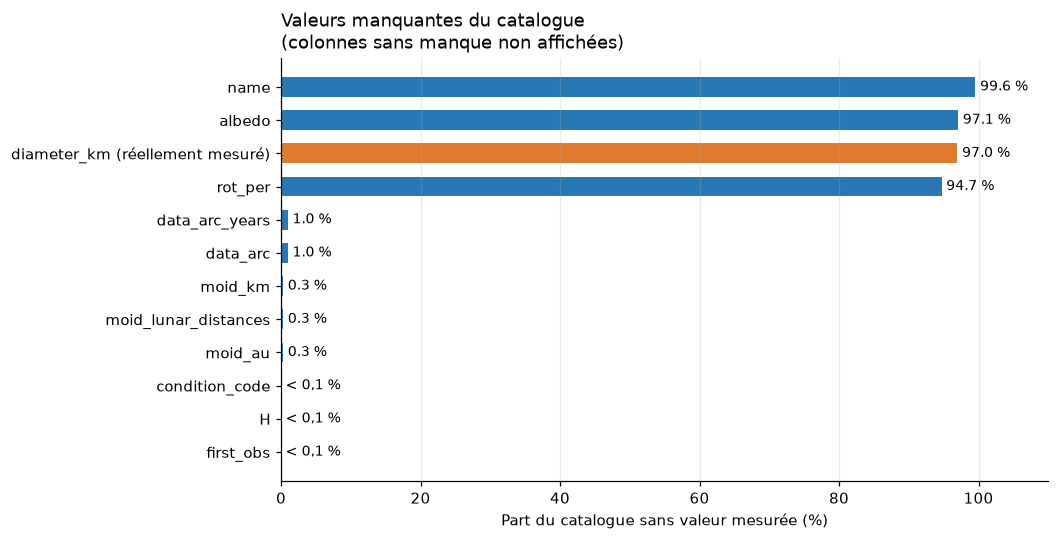

In [6]:
missing = asteroids.isna().mean().mul(100)
missing["diameter_km (réellement mesuré)"] = asteroids["diameter_is_estimated"].mean() * 100
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [ORANGE if "diameter" in c else BLUE for c in missing.index]
bars = ax.barh(missing.index, missing.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f} %" if v >= 0.1 else "< 0,1 %" for v in missing.values], padding=3, fontsize=9)
ax.set_xlabel("Part du catalogue sans valeur mesurée (%)")
ax.set_xlim(0, 110)
ax.set_title("Valeurs manquantes du catalogue\n(colonnes sans manque non affichées)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "valeurs_manquantes")
plt.show()

missing.rename("pourcentage_manquant").to_frame().sort_values(
    "pourcentage_manquant", ascending=False).to_csv(REPORT_DIR / "valeurs_manquantes.csv")

In [7]:
# Les diamètres « estimés » suivent-ils exactement la formule D = 1329 / √albédo × 10^(−H/5) ?
est = asteroids[asteroids["diameter_is_estimated"]]
implied_albedo = (1329 * 10 ** (-est["H"] / 5) / est["diameter_km"]) ** 2
print(f"Albédo implicite des diamètres estimés : moyenne {implied_albedo.mean():.4f}, "
      f"écart-type {implied_albedo.std():.1e}")

measured = asteroids[~asteroids["diameter_is_estimated"]]
print(f"Diamètres réellement mesurés : {fmt(len(measured))} objets "
      f"({len(measured) / len(asteroids):.1%}), dont {measured['albedo'].notna().mean():.0%} avec albédo")

Albédo implicite des diamètres estimés : moyenne 0.1400, écart-type 2.8e-17
Diamètres réellement mesurés : 1 246 objets (3.0%), dont 96% avec albédo


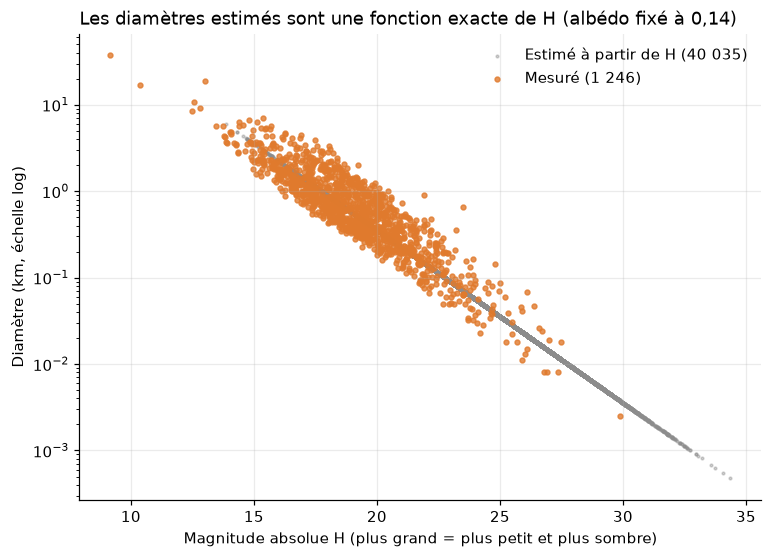

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(est["H"], est["diameter_km"], s=3, color=GREY, alpha=0.4,
           label=f"Estimé à partir de H ({fmt(len(est))})", rasterized=True)
ax.scatter(measured["H"], measured["diameter_km"], s=10, color=ORANGE, alpha=0.8,
           label=f"Mesuré ({fmt(len(measured))})")
ax.set_yscale("log")
ax.set_xlabel("Magnitude absolue H (plus grand = plus petit et plus sombre)")
ax.set_ylabel("Diamètre (km, échelle log)")
ax.set_title("Les diamètres estimés sont une fonction exacte de H (albédo fixé à 0,14)", loc="left")
ax.legend(frameon=False)
save(fig, "diametre_mesure_vs_estime")
plt.show()

**Conséquences pour la suite :**

- **97 % des diamètres sont calculés à partir de H avec un albédo fixe de 0,14.** Pour ces objets, la colonne `diameter_km` n'apporte aucune information de plus que H.
- **Étape 4 (régression du diamètre) :** il faut entraîner et évaluer le modèle **uniquement sur les ~1 250 diamètres mesurés**. Sinon, le modèle réapprend la formule et obtient un R² ≈ 1 sans intérêt.
- `size_category` est dérivée du diamètre, donc de H. Elle pose le même problème.
- L'albédo manque pour 97 % des objets. On ne peut donc pas l'utiliser directement comme variable sur tout le catalogue.

## 4. Distributions du catalogue

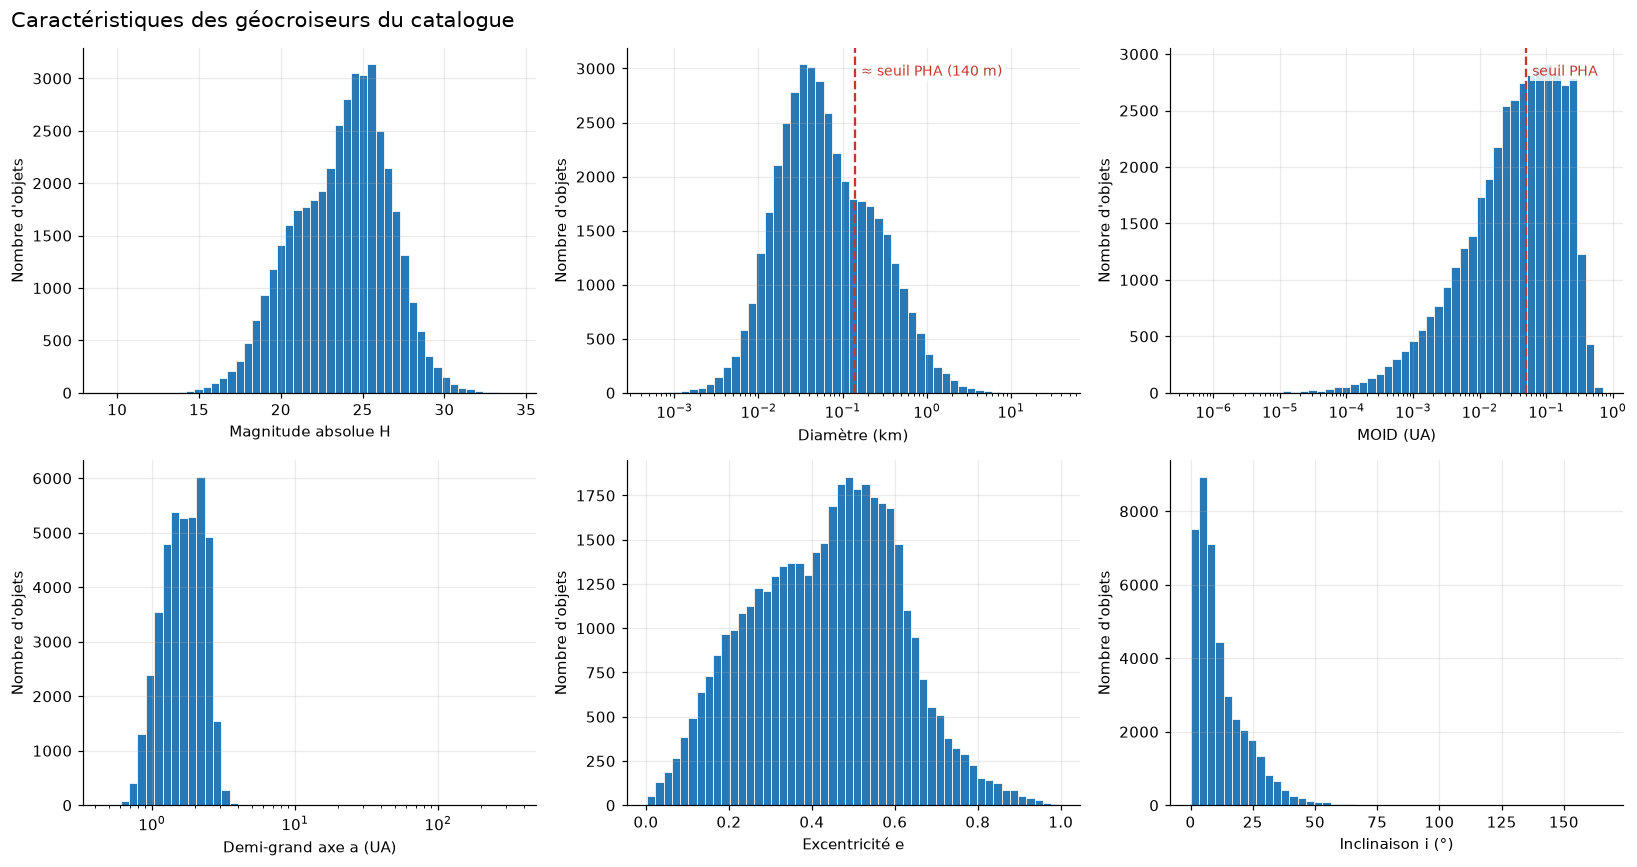

In [9]:
specs = [
    ("H", "Magnitude absolue H", False, None),
    ("diameter_km", "Diamètre (km)", True, 0.14),
    ("moid_au", "MOID (UA)", True, 0.05),
    ("a", "Demi-grand axe a (UA)", True, None),
    ("e", "Excentricité e", False, None),
    ("i", "Inclinaison i (°)", False, None),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, label, log, ref) in zip(axes.flat, specs):
    v = asteroids[col].dropna()
    v = v[v > 0] if log else v
    bins = np.logspace(np.log10(v.min()), np.log10(v.max()), 50) if log else 50
    ax.hist(v, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    if log:
        ax.set_xscale("log")
    if ref is not None:
        ax.axvline(ref, color=RED, ls="--", lw=1.5)
        ax.annotate("seuil PHA" if col == "moid_au" else "≈ seuil PHA (140 m)",
                    xy=(ref, 0.92), xycoords=("data", "axes fraction"),
                    xytext=(4, 0), textcoords="offset points", color=RED, fontsize=9, bbox=LABEL_BOX)
    ax.set_xlabel(label)
    ax.set_ylabel("Nombre d'objets")
fig.suptitle("Caractéristiques des géocroiseurs du catalogue", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
save(fig, "distributions_catalogue")
plt.show()

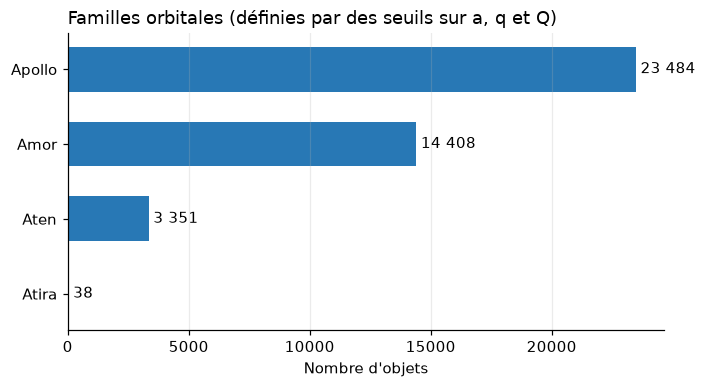

In [10]:
cls = (asteroids["class"].value_counts()
       .rename({"APO": "Apollo", "AMO": "Amor", "ATE": "Aten", "IEO": "Atira"}))
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(cls.index[::-1], cls.values[::-1], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[fmt(v) for v in cls.values[::-1]], padding=3)
ax.set_xlabel("Nombre d'objets")
ax.set_title("Familles orbitales (définies par des seuils sur a, q et Q)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "familles_orbitales")
plt.show()

## 5. La cible `pha` : déséquilibre et fuite de données

Un objet est classé **PHA** (Potentially Hazardous Asteroid) si **MOID ≤ 0,05 UA et H ≤ 22**. On vérifie si le label du fichier suit bien cette règle.

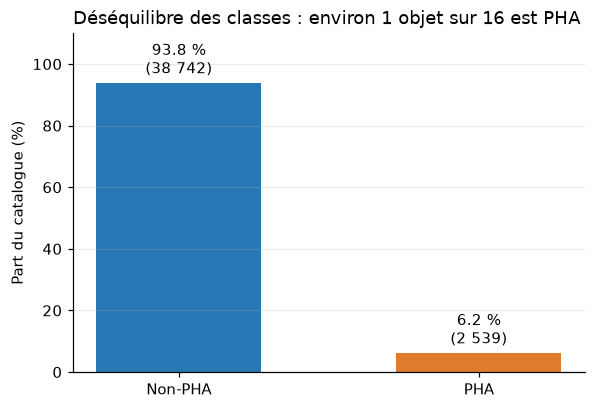

In [11]:
counts = asteroids["pha"].value_counts().reindex([False, True])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Non-PHA", "PHA"], pct.values, color=[BLUE, ORANGE], width=0.55)
ax.bar_label(bars, labels=[f"{p:.1f} %\n({fmt(c)})" for p, c in zip(pct, counts)], padding=3)
ax.set_ylabel("Part du catalogue (%)")
ax.set_ylim(0, 110)
ax.set_title("Déséquilibre des classes : environ 1 objet sur 16 est PHA", loc="left")
ax.grid(axis="x", visible=False)
save(fig, "repartition_pha")
plt.show()

pd.DataFrame({"effectif": counts, "pourcentage": pct}).to_csv(REPORT_DIR / "repartition_pha.csv")

In [12]:
rule = (asteroids["moid_au"] <= 0.05) & (asteroids["H"] <= 22)
agreement = (rule == asteroids["pha"]).mean()
print(f"Le label pha est égal à la règle (MOID ≤ 0,05 et H ≤ 22) pour {agreement:.2%} des objets.")
pd.crosstab(asteroids["pha"], rule, rownames=["pha (fichier)"], colnames=["règle MOID/H"])

Le label pha est égal à la règle (MOID ≤ 0,05 et H ≤ 22) pour 99.86% des objets.


règle MOID/H,False,True
pha (fichier),,
False,38722,20
True,36,2503


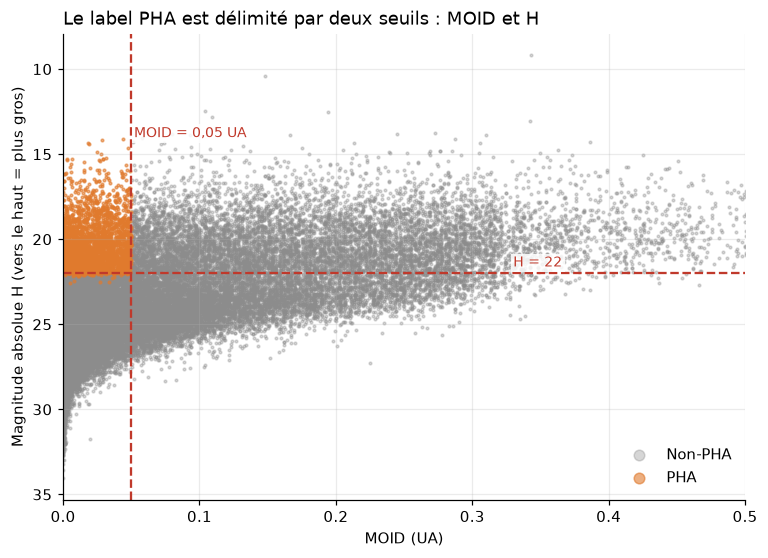

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for flag, color, label in [(False, GREY, "Non-PHA"), (True, ORANGE, "PHA")]:
    d = asteroids[asteroids["pha"] == flag]
    ax.scatter(d["moid_au"], d["H"], s=3, alpha=0.35 if not flag else 0.6,
               color=color, label=label, rasterized=True)
ax.axvline(0.05, color=RED, ls="--", lw=1.5)
ax.axhline(22, color=RED, ls="--", lw=1.5)
ax.text(0.052, 14, "MOID = 0,05 UA", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.text(0.33, 21.6, "H = 22", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlim(0, 0.5)
ax.invert_yaxis()
ax.set_xlabel("MOID (UA)")
ax.set_ylabel("Magnitude absolue H (vers le haut = plus gros)")
ax.set_title("Le label PHA est délimité par deux seuils : MOID et H", loc="left")
ax.legend(frameon=False, markerscale=4, loc="lower right")
save(fig, "fuite_pha_moid_h")
plt.show()

**Conséquence (pilier 2, absence de fuite) :** `pha` est presque une fonction déterministe de MOID et H. Un modèle qui reçoit ces deux variables atteindrait un rappel proche de 100 % sans rien apprendre. Pour la classification de l'étape 5, il faut **retirer `moid_au`, `moid_km`, `moid_lunar_distances`, `H` et toutes les colonnes dérivées de H** (`diameter_*`, `size_category`), ou bien choisir une autre cible.

## 6. Distributions des approches

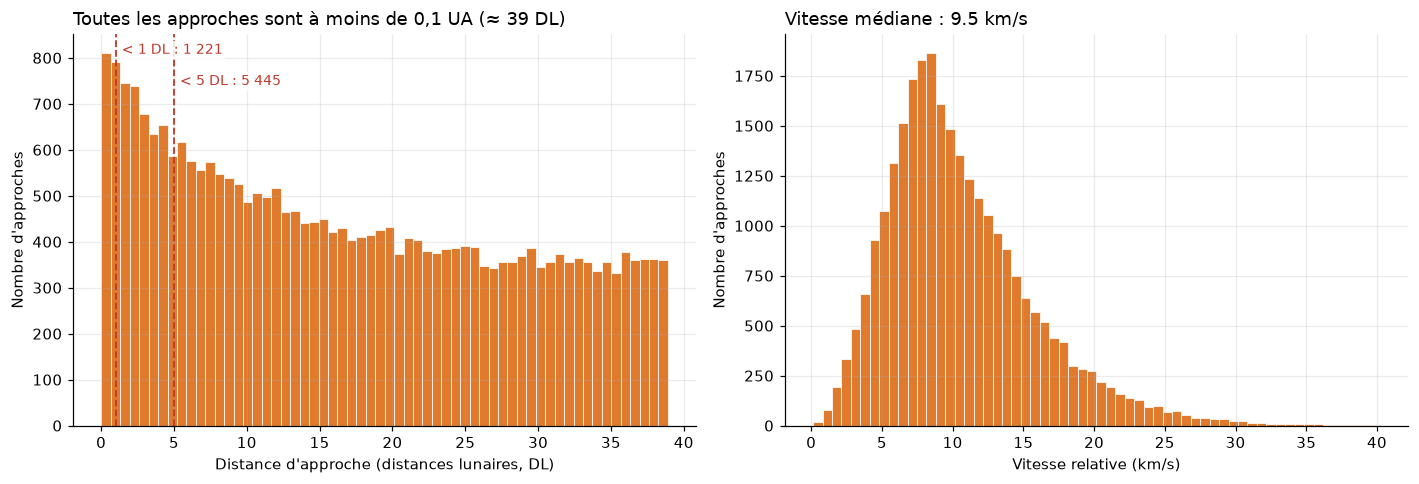

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.hist(approaches["dist_lunar"], bins=60, color=ORANGE, edgecolor="white", linewidth=0.5)
for ld in (1, 5):
    n = (approaches["dist_lunar"] < ld).sum()
    ax.axvline(ld, color=RED, ls="--", lw=1.2)
    ax.annotate(f"< {ld} DL : {fmt(n)}", xy=(ld, 0.95 - 0.08 * (ld == 5)),
                xycoords=("data", "axes fraction"), xytext=(4, 0),
                textcoords="offset points", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Distance d'approche (distances lunaires, DL)")
ax.set_ylabel("Nombre d'approches")
ax.set_title("Toutes les approches sont à moins de 0,1 UA (≈ 39 DL)", loc="left")

ax = axes[1]
ax.hist(approaches["velocity_km_s"], bins=60, color=ORANGE, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Vitesse relative (km/s)")
ax.set_ylabel("Nombre d'approches")
ax.set_title(f"Vitesse médiane : {approaches['velocity_km_s'].median():.1f} km/s", loc="left")

fig.tight_layout()
save(fig, "distributions_approches")
plt.show()

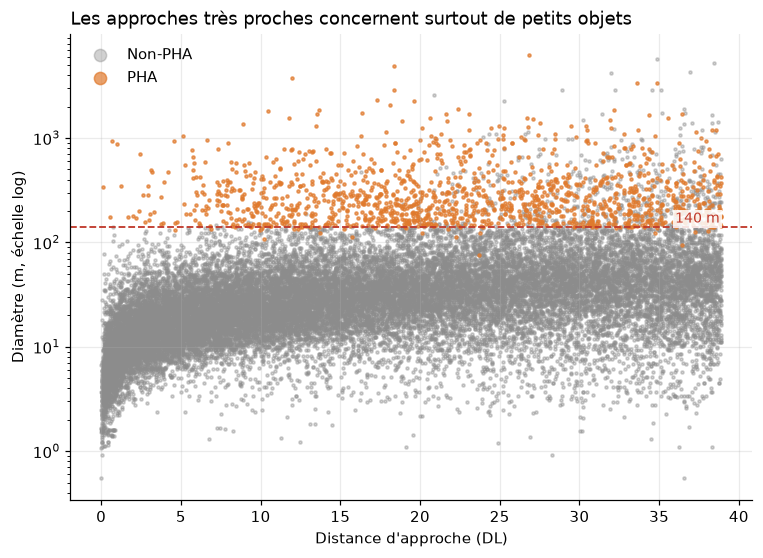

Part des approches faites par des PHA : 5.0%
Diamètre médian des objets en approche : 27 m


In [15]:
merged = approaches.merge(
    asteroids[["pdes", "pha", "diameter_km", "diameter_is_estimated", "first_obs"]],
    left_on="designation", right_on="pdes", how="left")

fig, ax = plt.subplots(figsize=(8, 5.5))
for flag, color, label in [(False, GREY, "Non-PHA"), (True, ORANGE, "PHA")]:
    d = merged[merged["pha"] == flag]
    ax.scatter(d["dist_lunar"], d["diameter_km"] * 1000, s=4, alpha=0.4 if not flag else 0.7,
               color=color, label=label, rasterized=True)
ax.axhline(140, color=RED, ls="--", lw=1.2)
ax.text(36, 155, "140 m", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_yscale("log")
ax.set_xlabel("Distance d'approche (DL)")
ax.set_ylabel("Diamètre (m, échelle log)")
ax.set_title("Les approches très proches concernent surtout de petits objets", loc="left")
ax.legend(frameon=False, markerscale=4)
save(fig, "approches_distance_vs_taille")
plt.show()

print(f"Part des approches faites par des PHA : {merged['pha'].mean():.1%}")
print(f"Diamètre médian des objets en approche : {merged['diameter_km'].median() * 1000:.0f} m")

## 7. Biais d'observation dans le temps

Le fichier d'approches couvre 2015–2035. On ne connaît pourtant les approches futures que pour les objets **déjà découverts**. On compare donc le nombre d'approches par année avec le nombre de découvertes par année.

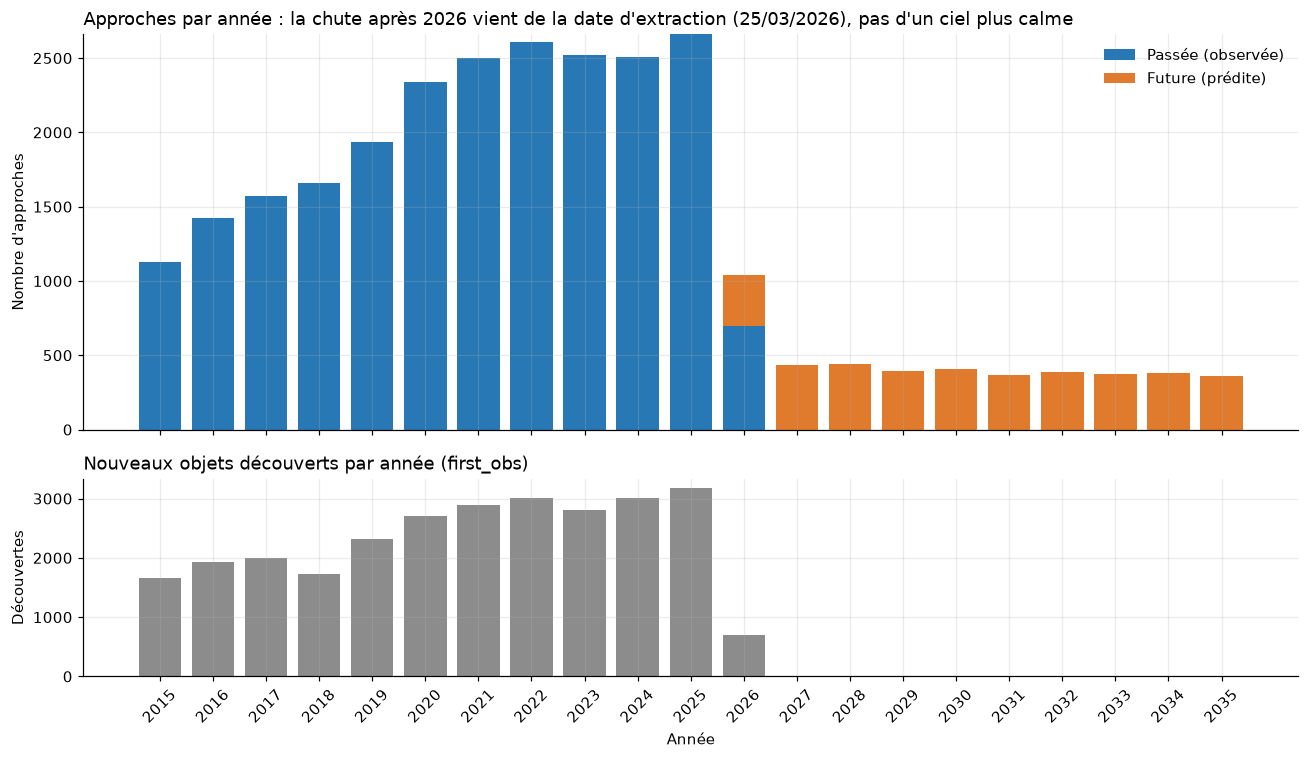

In [16]:
cutoff = approaches.loc[approaches["is_future"], "date"].min()
years = range(2015, 2036)
by_year = approaches.groupby([approaches["date"].dt.year, "is_future"]).size().unstack(fill_value=0)
by_year = by_year.reindex(years, fill_value=0)
discoveries = asteroids["first_obs"].dt.year.value_counts().reindex(years, fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.bar(by_year.index, by_year[False], color=BLUE, label="Passée (observée)")
ax.bar(by_year.index, by_year[True], bottom=by_year[False], color=ORANGE, label="Future (prédite)")
ax.set_ylabel("Nombre d'approches")
ax.set_title(f"Approches par année : la chute après 2026 vient de la date d'extraction "
             f"({cutoff:%d/%m/%Y}), pas d'un ciel plus calme", loc="left")
ax.legend(frameon=False)

ax = axes[1]
ax.bar(discoveries.index, discoveries.values, color=GREY)
ax.set_ylabel("Découvertes")
ax.set_xlabel("Année")
ax.set_title("Nouveaux objets découverts par année (first_obs)", loc="left")
ax.set_xticks(list(years))
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
save(fig, "approches_par_annee_biais")
plt.show()

by_year.rename(columns={False: "passees", True: "futures"}).assign(
    decouvertes=discoveries).to_csv(REPORT_DIR / "approches_par_annee.csv")

In [17]:
before_discovery = (merged["date"] < merged["first_obs"]).mean()
per_object = approaches["designation"].value_counts()
print(f"Approches survenues AVANT la découverte de l'objet : {before_discovery:.1%}")
print(f"Approches par objet : médiane {per_object.median():.0f}, "
      f"{(per_object == 1).mean():.0%} des objets n'ont qu'une seule approche, max {per_object.max()}")

Approches survenues AVANT la découverte de l'objet : 34.1%
Approches par objet : médiane 1, 80% des objets n'ont qu'une seule approche, max 21


**Lecture :**

- **La hausse de 2015 à 2025 suit celle des découvertes.** Elle reflète la capacité des relevés télescopiques, pas une augmentation réelle du nombre d'approches.
- **La chute après mars 2026** s'explique par l'absence, dans les prévisions, des objets qui ne sont pas encore découverts.
- **Environ un tiers des approches passées ont eu lieu avant la découverte de l'objet.** Elles ont été reconstituées après coup.
- **La plupart des objets n'ont qu'une seule approche** dans la fenêtre. Des variables du type « historique des approches passées » seront donc vides pour la majorité du catalogue.

Ces points serviront à formuler la cible de l'étape 3 et à rester prudent dans les conclusions présentées à la PDCO.

## 8. Synthèse et implications pour les étapes suivantes

In [18]:
summary = pd.DataFrame({
    "constat": [
        "Objets au catalogue",
        "Part de PHA",
        "Accord label pha / règle MOID-H",
        "Diamètres réellement mesurés",
        "Événements d'approche (2015–2035)",
        "Approches à moins de 1 DL",
        "Approches futures (après extraction)",
        "Objets avec une seule approche",
    ],
    "valeur": [
        fmt(len(asteroids)),
        f"{asteroids['pha'].mean():.1%}",
        f"{agreement:.1%}",
        f"{fmt(len(measured))} ({len(measured) / len(asteroids):.1%})",
        fmt(len(approaches)),
        fmt((approaches['dist_lunar'] < 1).sum()),
        fmt(approaches['is_future'].sum()),
        f"{(per_object == 1).mean():.0%}",
    ],
})
summary.to_csv(REPORT_DIR / "synthese_eda.csv", index=False)
summary

,constat,valeur
0,Objets au catalogue,41 281
1,Part de PHA,6.2%
2,Accord label pha / règle MOID-H,99.9%
3,Diamètres réellement mesurés,1 246 (3.0%)
4,Événements d'approche (2015–2035),27 430
5,Approches à moins de 1 DL,1 221
6,Approches futures (après extraction),3 888
7,Objets avec une seule approche,80%


| Constat | Décision pour la suite |
|---|---|
| `pha` ≈ règle sur MOID et H | Étape 5 : exclure MOID, H et les colonnes dérivées de H si `pha` est la cible |
| 97 % des diamètres = formule à partir de H | Étape 4 : entraîner et évaluer la régression **uniquement sur les diamètres mesurés** |
| 6 % de PHA | `class_weight="balanced"`, split stratifié, métriques rappel / F1 / PR-AUC plutôt que l'accuracy |
| Biais de découverte et date d'extraction | Étape 3 : découpage temporel explicite (variables ≤ date de coupure, cible après), et prudence sur les tendances annuelles |
| Une seule approche pour la plupart des objets | Les variables d'historique d'approche sont peu informatives : privilégier les éléments orbitaux (a, e, i, q, ad, période) |
| Familles orbitales définies par des seuils | Étape 6 : ne pas présenter le clustering comme une redécouverte d'Apollo, Aten, Amor et Atira ; chercher plutôt des profils de risque |